# 🎓 Predicting Student Mental Health Score from Social Media Usage

**Problem:** We're predicting a student's `Mental_Health_Score` (a continuous score from ~3 to ~10) using their social media habits, study time, sleep, physical activity, and stress level. This is a **regression** problem since the target is a number, not a category.

**Dataset:** `Student_Social_Media_And_Mental_Health_Impact.csv` — 5,000 students, 13 columns covering demographics (Age, Gender, Country), platform usage (Avg_Daily_Usage_Hours, Daily_Unlocks, Most_Used_Platform), lifestyle (Study_Hours, Sleep_Hours_Per_Night, Physical_Activity_Hours), and Stress_Level.



## 1. Import Libraries

We're grouping imports by purpose: data handling, visualization, preprocessing, models, evaluation, and saving. Keeping imports grouped like this makes it easy to see at a glance what the notebook is going to do.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the Dataset

We load the CSV and take a first look at its shape and the first few rows. This is always the very first step — you can't make any decisions about a dataset until you've actually looked at it.

In [2]:
df = pd.read_csv('Student_Social_Media_And_Mental_Health_Impact.csv')

In [3]:
# number of rows and columns
df.shape

(5000, 13)

In [4]:
# look at first 5 rows.
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 3. Basic Checks

Before cleaning or plotting anything, we check the column types, missing values, duplicate rows and the basic statistics of every numeric column.

In [5]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(2)

📌 **Reading this:** no missing values, but there are **2 duplicate rows**. We remove them in the Data Cleaning step, because duplicated rows can quietly bias a model toward whatever got repeated.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 507.9 KB


In [8]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


📌 **Reading this:** Most columns look reasonable — but look closely at `Physical_Activity_Hours`: the **minimum value is -0.4**. Negative hours aren't physically possible, so this is a data-entry glitch, not a real value. We'll fix this properly in the **Data Cleaning** step below instead of ignoring it.

## 4. Exploratory Data Analysis (EDA)

We'll keep this focused — six plots, each answering one specific question about the data, not a wall of charts for the sake of it.

### 4.1 — Distribution of the target (`Mental_Health_Score`)

Before predicting anything, we need to understand the shape of what we're predicting.

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

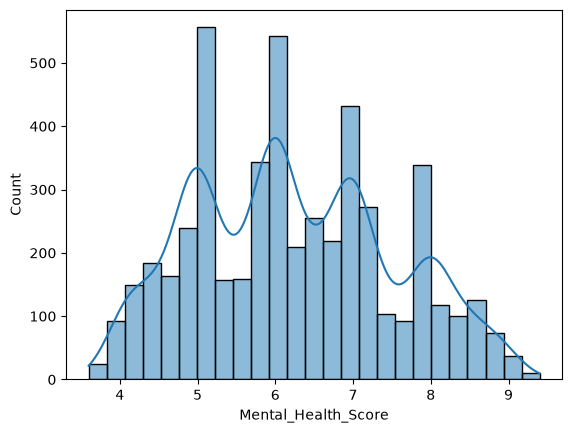

In [9]:
sns.histplot((df['Mental_Health_Score']) , kde=True)

### 4.2 — Correlation heatmap

Which numeric features actually move together with the target?

<Axes: >

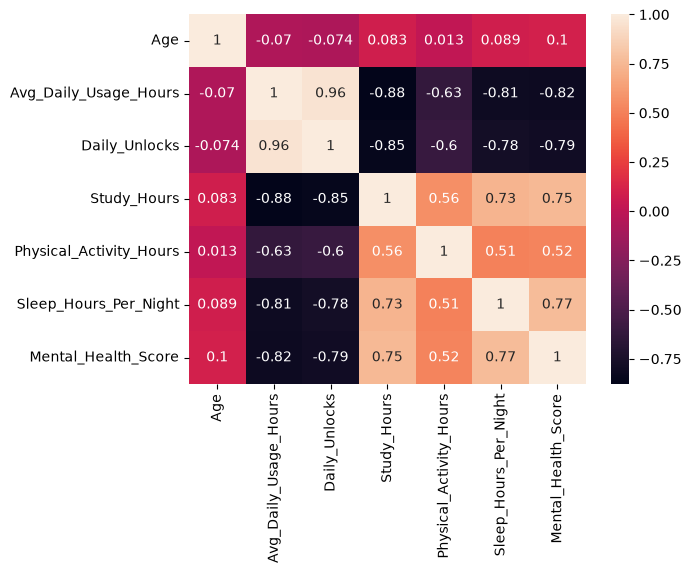

In [10]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

### 4.3 — Stress Level vs Mental Health Score

Does higher stress genuinely come with a lower score?

In [11]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='str')

In [12]:
df['Stress_Level'].unique()

<StringArray>
['Medium', 'Low', 'Very High', 'High']
Length: 4, dtype: str

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

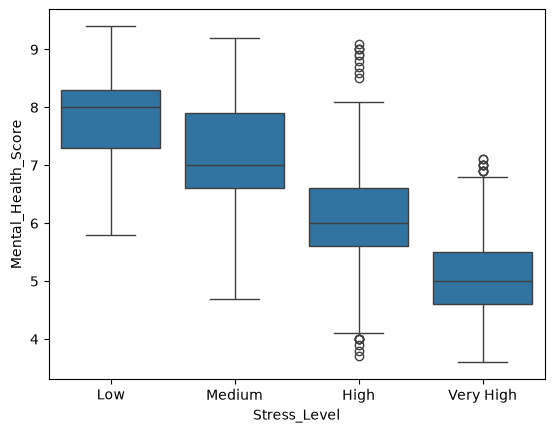

In [13]:
order = ['Low','Medium','High', 'Very High']
sns.boxplot(x='Stress_Level' ,y='Mental_Health_Score',data=df, order=order)

### 4.4 — Daily Usage Hours vs Mental Health Score

Does more time on social media relate to a lower score?

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

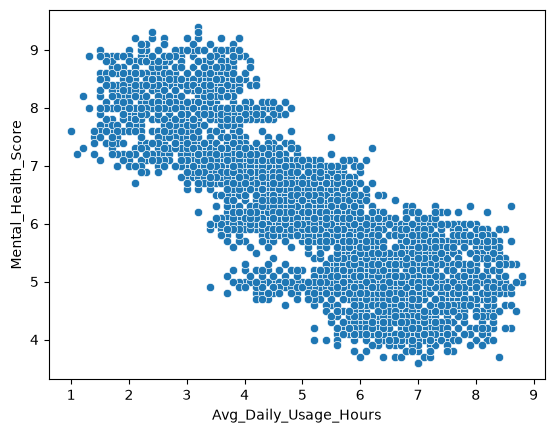

In [14]:
sns.scatterplot(x="Avg_Daily_Usage_Hours",y="Mental_Health_Score" , data=df)

### 4.5 — Sleep Hours vs Mental Health Score

Sleep is one of the most commonly cited mental health factors — does the data back that up?

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

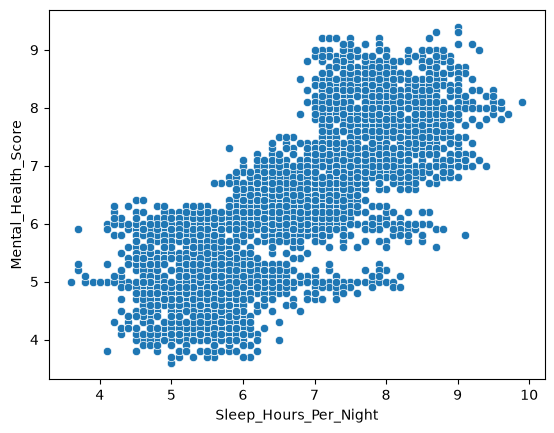

In [15]:
sns.scatterplot(x="Sleep_Hours_Per_Night",y="Mental_Health_Score" , data=df)

### 4.6 — Most Used Platform (count)

A quick look at which platforms are most common in our dataset.

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

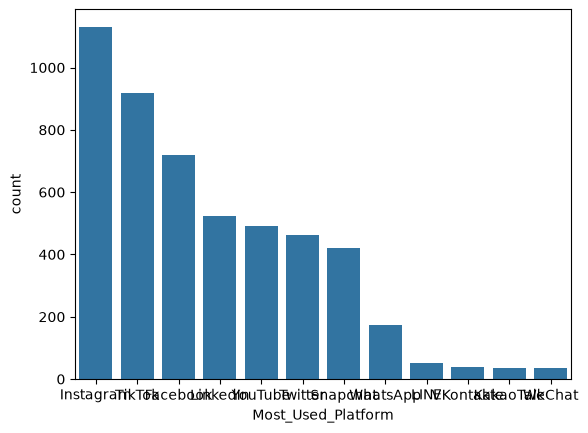

In [16]:
sns.countplot(x='Most_Used_Platform',order =df["Most_Used_Platform"].value_counts().index, data=df)

**Checking Outliers**

In [17]:
num_features = df.select_dtypes(include='number')  #int64 or float64
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


## 5. Data Cleaning

Two real issues to fix here — everything else in this dataset is already clean, so we don't manufacture cleaning steps that aren't needed.

In [18]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [19]:
# 1. drop duplicates
df = df.drop_duplicates()

In [20]:
# 2. convert impossible negative activity hours to 0
df['Physical_Activity_Hours']= df['Physical_Activity_Hours'].clip(lower=0)

📌 **Why `clip(lower=0)` and not dropping the row:** the rest of that student's data (age, study hours, stress level, etc.) is still valid and useful — throwing away the whole row over one bad value wastes good data. Clipping caps the impossible value at the nearest realistic one (0 hours) without discarding everything else about that student.

We're not dropping any columns either — every column here has a plausible reason to matter for predicting mental health, and we already confirmed none of them are empty or constant.

## 6. Skewness

**What skewness is:** a measure of how lopsided a numeric column's distribution is. A value near 0 means roughly symmetric (bell-shaped); a large positive or negative value means the data leans heavily to one side, with a long tail.

**Why it matters:** models like Linear Regression assume features are roughly well-behaved. A heavily skewed column (think: a long tail of extreme values) can quietly drag the model's predictions in that direction. Tree-based models like Random Forest don't care about skew — but since we're also training a Linear Regression baseline, it's worth fixing.

In [21]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()

#  is value is neat to zero = centralised
# negative -> left skewed
# positive (greater than 0) -> Right Skewed

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

## 7. Feature Engineering

**One meaningful engineered feature here:** grouping `Country`.

- `Country` has **111 unique values** in this dataset — one-hot encoding that directly would add 110 mostly-empty columns, which hurts the model far more than it helps (this is called high cardinality).
- Dropping `Country` entirely throws away signal that may be useful.
- **The fix:** keep the 10 most frequent values as their own category, and bucket everything else into `"Other"`.

**Important detail:** the raw data already contains a value called `"Other"` (1,880 rows), and it is the most frequent value. So the top 10 values are `"Other"` plus **9 real countries**, and after grouping we end up with **10 groups** in total.

In [22]:
top_countries=df["Country"].value_counts().index[0:10]

In [23]:
def group_countries(country):
    if country in top_countries:
        return country
    else:
        return 'Other'

In [24]:
df['Grouped_country'] = df['Country'].apply(group_countries)

In [25]:
df['Grouped_country'].value_counts()

Grouped_country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

📌 **Result:** we went from 111 raw categories down to 10 manageable ones (9 named countries + `"Other"`). The FastAPI backend uses this exact same list, so a country typed on the website is grouped the same way as during training.

## 8. Encoding Strategy

Before we jump into code, let's decide *how* each categorical column should be encoded — this decision matters more than the code itself.

- **`Stress_Level` → Ordinal Encoding.** Its categories have a real, meaningful order: Low < Medium < High < Very High. We already saw in EDA (section 4.3) that the score drops step by step as stress increases — encoding it as 0, 1, 2, 3 preserves that order for the model.
- **`Gender`, `Academic_Level`, `Most_Used_Platform`, `Purpose_Of_Use`, `Grouped_country` → One-Hot Encoding.** These categories have **no natural order** — "Instagram" isn't "greater than" "LinkedIn". One-hot encoding creates a separate 0/1 column per category so the model doesn't accidentally assume a false ranking.

We'll implement both of these inside a single `ColumnTransformer` in the next step, rather than doing it manually column by column — that keeps preprocessing consistent and reusable.

## 9. Train-Test Split

**Why we split:** we need data the model has never seen to honestly check how well it generalizes. If we evaluate on the same data we trained on, the model can just "memorize" the answers and look artificially good.

**Common ratios:** 80/20 or 70/30 are both standard. We'll use an 80/20 split here — with 4,998 rows, that leaves 1,000 rows for the test set.

We split **before** fitting any preprocessing, so scaling and encoding are learned only from the training set (this avoids data leakage).

In [26]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score', 'Grouped_country'],
      dtype='str')

In [27]:
from sklearn.model_selection import train_test_split

skewed_col         = ['Study_Hours']
other_numeric_cols = ['Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Age',
                      'Sleep_Hours_Per_Night', 'Physical_Activity_Hours']
ordinal_col        = ['Stress_Level']
nominal_cols       = ['Gender', 'Academic_Level',
                      'Most_Used_Platform', 'Purpose_Of_Use',
                      'Grouped_country']
feature_col        = skewed_col + other_numeric_cols + ordinal_col + nominal_cols

x = df[feature_col]
y = df['Mental_Health_Score']

# train test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)
print(x_train.shape, x_test.shape)

(3998, 12) (1000, 12)


## 10. Preprocessing using ColumnTransformer

Our columns need **different treatment**:

- `Study_Hours` (the most skewed one) → `log1p` transform → scale
- The other numeric columns → scale (no skew to fix)
- `Stress_Level` → `OrdinalEncoder` with an **explicit order**
- The nominal columns → `OneHotEncoder` (`handle_unknown='ignore'`, so an unseen category at prediction time does not crash the model)

We don't add an imputer because the dataset has no missing values, and the FastAPI backend makes every field required, so missing values can never reach the model.

`ColumnTransformer` glues all of this into **one object** that applies the right transformation to the right column type in a single `.fit()` / `.transform()` call — no manual column-by-column juggling.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Skewed feature: log1p, then scale
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler())
])

# 2. Other numeric features: scale
plain_numeric_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

# 3. Ordinal feature: explicit order
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

# 4. Nominal features: one-hot
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

# 5. Column transformer (which pipeline, which columns)
preprocessor = ColumnTransformer(transformers=[
    ('skewed',        skew_pipeline,          skewed_col),
    ('plain_numeric', plain_numeric_pipeline, other_numeric_cols),
    ('ordinal',       ordinal_pipeline,       ordinal_col),
    ('nominal',       nominal_pipeline,       nominal_cols)
])

## 11. Build a Pipeline

**Why Pipeline matters:** a `Pipeline` chains preprocessing and the model into a single object. Calling `.fit()` once does both steps in the correct order, and calling `.predict()` on brand-new raw data automatically applies the exact same preprocessing that was used during training — no risk of forgetting a step or applying it inconsistently.

**Why companies prefer this:** when this model gets deployed (which we're doing in Part 2 with FastAPI), the API doesn't need to know *anything* about scaling, encoding, or log transforms — it just loads one saved pipeline object and calls `.predict()` on raw input. That's a huge reduction in what can go wrong in production.

We'll build two pipelines below — one per model — so we can fairly compare them.

## 12. Model Building

We're comparing **two models** here because the comparison itself teaches something useful — a plain Linear Regression baseline versus a Random Forest, which can capture the non-linear patterns we spotted back in EDA (section 4.4).

### 12.1 — Baseline: Linear Regression

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(x_train, y_train)
lr_preds       = lr_pipeline.predict(x_test)
lr_preds_train = lr_pipeline.predict(x_train)

lr_r2_testing  = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae         = mean_absolute_error(y_test, lr_preds)

print(f"Train R2 : {lr_r2_training:.4f}")
print(f"Test R2  : {lr_r2_testing:.4f}")
print(f"Test MAE : {lr_mae:.4f}")

Train R2 : 0.7256
Test R2  : 0.7428
Test MAE : 0.5339


### 12.2 — Random Forest (default settings)

Same preprocessor, different model at the end — that's the entire point of building the pipeline once.

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(x_train, y_train)
rf_preds       = rf_pipeline.predict(x_test)
rf_preds_train = rf_pipeline.predict(x_train)

rf_r2_testing  = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae         = mean_absolute_error(y_test, rf_preds)

print(f"Train R2 : {rf_r2_training:.4f}")
print(f"Test R2  : {rf_r2_testing:.4f}")
print(f"Test MAE : {rf_mae:.4f}")

Train R2 : 0.9827
Test R2  : 0.8905
Test MAE : 0.3268


### 12.3 — Hyperparameter Tuning the Random Forest

When tuning a `Pipeline`, each parameter needs to be prefixed with the step name (`regressor__`) so `RandomizedSearchCV` knows which part of the pipeline it belongs to. We use `RandomizedSearchCV` instead of a full grid search — it samples a fixed number of combinations instead of testing every single one, which is far faster.

`max_depth` includes `None` (no limit, the default). Without it the search could never pick the unlimited depth that the default model uses, so the tuned model would be forced to be shallower than the default one.

In [31]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'regressor__n_estimators'      : [100, 200, 300],
    'regressor__max_depth'         : [5, 10, 15, 20, None],
    'regressor__min_samples_split' : [2, 5, 10],
    'regressor__min_samples_leaf'  : [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator           = rf_pipeline,
    param_distributions = param_grid,
    n_iter              = 15,
    cv                  = 5,
    scoring             = 'r2',
    random_state        = 42,
    n_jobs              = -1   # use all CPU cores
)
random_search.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__max_depth': [5, 10, ...], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': [2, 5, ...], 'regressor__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Ra

In [32]:
random_search.best_params_

{'regressor__n_estimators': 300,
 'regressor__min_samples_split': 2,
 'regressor__min_samples_leaf': 1,
 'regressor__max_depth': None}

In [33]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(x_test)
print(f"Best CV R2 (tuned)  : {random_search.best_score_:.4f}")
print(f"Test R2 (tuned)     : {r2_score(y_test, rf_best_preds):.4f}")
print(f"Test MAE (tuned)    : {mean_absolute_error(y_test, rf_best_preds):.4f}")

Best CV R2 (tuned)  : 0.8600
Test R2 (tuned)     : 0.8910
Test MAE (tuned)    : 0.3255


## 13. Model Evaluation

**Metrics, explained simply:**
- **R² Score** — how much of the variation in mental health scores our model explains, from 0 (no better than guessing the average) to 1 (perfect). 0.85 means the model explains 85% of the variation. R² is not "accuracy" — accuracy is a classification metric.
- **MAE (Mean Absolute Error)** — on average, how far off our prediction is, in the original units (score points). Easy to explain to a non-technical person.
- **RMSE (Root Mean Squared Error)** — similar to MAE, but penalizes big mistakes more heavily.

We also add a **baseline** that always predicts the average training score. A useful model has to beat it clearly.

In [34]:
# baseline: always predict the mean of the training target
baseline_preds = np.full(len(y_test), y_train.mean())
baseline_mae   = mean_absolute_error(y_test, baseline_preds)
baseline_rmse  = np.sqrt(mean_squared_error(y_test, baseline_preds))

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

rf_tuned_preds    = rf_best_pipeline.predict(x_test)
rf_tuned_rmse     = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training = r2_score(y_train, rf_best_pipeline.predict(x_train))
rf_tuned_mae      = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2       = r2_score(y_test, rf_tuned_preds)

results = pd.DataFrame({
    'Model'       : ['Baseline (mean)', 'Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'Test RMSE'   : [baseline_rmse, lr_rmse, rf_rmse, rf_tuned_rmse],
    'Test R2'     : [0.0, lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Test MAE'    : [baseline_mae, lr_mae, rf_mae, rf_tuned_mae],
    'Train R2'    : [0.0, lr_r2_training, rf_r2_training, rf_tuned_training]
}).round(3)

print(results.to_string(index=False))

                  Model  Test RMSE  Test R2  Test MAE  Train R2
        Baseline (mean)      1.337    0.000     1.128     0.000
      Linear Regression      0.678    0.743     0.534     0.726
Random Forest (default)      0.442    0.890     0.327     0.983
  Random Forest (tuned)      0.441    0.891     0.326     0.983


### 13.1 — Choosing the final model with cross-validation

A single test split can be lucky or unlucky, and if we pick the model by looking at the test set we are quietly tuning on it. So we choose the final model by **5-fold cross-validation on the training set only**, and keep the test set just for the final report.

**Tie-break rule:** if two models are within 0.005 CV R² of each other, the difference is smaller than the noise between folds, so we keep the **smaller** model. A smaller Random Forest loads faster and uses less memory on the free hosting plan (512 MB RAM).

In [35]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
candidates = {
    'Linear Regression'      : lr_pipeline,
    'Random Forest (default)': rf_pipeline,
    'Random Forest (tuned)'  : rf_best_pipeline,
}

cv_scores = {}
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, x_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
    cv_scores[name] = scores.mean()
    print(f"{name:25s} CV R2 = {scores.mean():.3f} ± {scores.std():.3f}")

# candidates are listed from smallest to largest model
best_score = max(cv_scores.values())
best_name  = next(name for name, score in cv_scores.items() if best_score - score < 0.005)
final_pipeline = candidates[best_name]
print(f"\nChosen model: {best_name}")

Linear Regression         CV R2 = 0.721 ± 0.006


Random Forest (default)   CV R2 = 0.865 ± 0.008


Random Forest (tuned)     CV R2 = 0.866 ± 0.008

Chosen model: Random Forest (default)


### 13.2 — What the model relies on

Feature importance shows which inputs the Random Forest uses most. It also shows an important limitation of this dataset: the lifestyle columns are very strongly correlated with each other, so the model takes most of its information from screen time.

In [36]:
feature_names = final_pipeline.named_steps['preprocessor'].get_feature_names_out()
model_step    = final_pipeline.named_steps['regressor']

if hasattr(model_step, 'feature_importances_'):
    importance = pd.Series(model_step.feature_importances_, index=feature_names).sort_values(ascending=False)
    print(importance.head(10).round(3))

stress_num = df['Stress_Level'].map({'Low': 0, 'Medium': 1, 'High': 2, 'Very High': 3})
print('\nCorrelation of Stress_Level with Avg_Daily_Usage_Hours:',
      round(stress_num.corr(df['Avg_Daily_Usage_Hours']), 3))
print('Correlation of Daily_Unlocks with Avg_Daily_Usage_Hours:',
      round(df['Daily_Unlocks'].corr(df['Avg_Daily_Usage_Hours']), 3))

plain_numeric__Avg_Daily_Usage_Hours      0.688
plain_numeric__Sleep_Hours_Per_Night      0.102
plain_numeric__Daily_Unlocks              0.046
skewed__Study_Hours                       0.026
plain_numeric__Physical_Activity_Hours    0.026
plain_numeric__Age                        0.016
nominal__Purpose_Of_Use_Entertainment     0.009
nominal__Grouped_country_Other            0.006
nominal__Most_Used_Platform_Instagram     0.006
ordinal__Stress_Level                     0.006
dtype: float64

Correlation of Stress_Level with Avg_Daily_Usage_Hours: 0.873
Correlation of Daily_Unlocks with Avg_Daily_Usage_Hours: 0.96


📌 **Reading this:** screen time carries most of the importance. Stress level is strongly linked to the score, but it is also strongly linked to screen time, so once the model knows the screen time, stress adds very little. On the website this means changing only the stress level moves the score very little. Also, a Random Forest cannot predict outside the range it saw in training (for example screen time above 8.8 hours), so the website sliders are limited to the training range.

## 14. Save the Model

We save the **entire chosen pipeline** — preprocessing and model together — as a single file, not just the raw model. **Why:** if we only saved the Random Forest object, our FastAPI backend would need to manually recreate every encoding and scaling step by hand at prediction time, which is fragile and easy to get wrong. Saving the full pipeline means the backend just loads one file and calls `.predict()` on raw input — the pipeline handles everything internally, exactly the same way it did during training.

In [37]:
import joblib

# compress=3 makes the file much smaller without changing the model
joblib.dump(final_pipeline, 'Mental_Health_Model.pkl', compress=3)
print(f"Saved: {best_name}")

Saved: Random Forest (default)


## 15. Deployment

The saved `Mental_Health_Model.pkl` is loaded by the FastAPI backend (`main.py`), which validates every request with Pydantic, groups the country exactly like section 7, and calls `.predict()` on the raw input. A plain HTML/CSS/JavaScript page calls the API every time a slider moves. Both are deployed on Render.